# 01 EDA and leakage review (cities A and B)
Owner: P2

Region **Australia** (AUD). **A = Sydney, B = Melbourne**, snapshots of 2026-09-16. City C is not loaded here until week 1 is finished.

Reads the pipeline's tables (`bronze.listings_raw`, `silver.listings`), so run `00_run_pipeline` for both cities first. Nothing here writes to a table.

## Summary
*Numbers in [brackets] come from the last cell, `Facts for the summary`, after a full run.*

**What we now know**
- **Grain:** one row = one listing as it was on the snapshot date; `id` is unique in silver (duplicates removed: [n]).
- **Size:** Sydney [n] listings, Melbourne [n].
- **No price for a large share:** about **15% in Sydney and 26% in Melbourne** have no valid price (`is_valid_price = false`). Section 2.1 shows these are mostly inactive listings (blocked calendar, no recent reviews), so the price is *not applicable*, not *unknown*. They are **excluded** from every price analysis and from the model; they stay in silver for listing counts.
- **Other gaps stay NULL** and are structural, not random: review scores are NULL exactly when there are no reviews; bedrooms/beds are NULL mostly for rooms and studios; host response fields are NULL together (host never answered requests).
- **Price** is strongly right-skewed (median [x] AUD in Sydney, [x] in Melbourne); on a log scale it is roughly normal within a room type, so the model should predict `log(price)`.
- **Outliers:** [n] typed-in placeholder prices (9999, 99999...) to drop from training; [n] high/low outliers that look real (large homes); [n] long-stay listings (`minimum_nights > 30`) whose nightly price means something else.
- **Leakage:** `estimated_revenue_l365d` = price × estimated occupancy (holds for [x]% of rows) and is NULL whenever price is NULL. It must never be a feature.

**What we still don't know**
- Whether the advertised snapshot price is what guests pay (no seasonality, discounts or cleaning fee).
- Whether long-stay listings quote a real nightly rate or a monthly rate split by nights.
- How well neighbourhood-based features transfer to a city whose neighbourhoods the model has never seen (city C).

In [0]:
import os, sys
sys.path.append(os.path.abspath("../src"))
import importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from airbnb import config, eda
importlib.reload(eda)

pd.set_option("display.max_columns", 60)
dbutils.widgets.text("cities", ",".join(config.TRAIN_CITIES))
CITIES = [c.strip() for c in dbutils.widgets.get("cities").split(",") if c.strip()]

# City C stays unseen until the week-1 pipeline and model are tagged `week1-final`.
unseen = set(CITIES) - set(config.TRAIN_CITIES)
assert not unseen, f"{unseen} is not a training city. Compare it in 03_city_c, in week 2."

df_all = eda.load_silver(spark, CITIES)                                   # every listing
df = df_all[df_all["is_valid_price"].fillna(False).astype(bool)].copy()   # price analysis: valid prices only
print(f"silver rows: {len(df_all)}, with a valid price: {len(df)}")

silver rows: 46548, with a valid price: 36725


## 1. The dataset
**Grain: one row = one listing** as it looked on the snapshot date. Source: Inside Airbnb `listings.csv.gz` (detailed listings), latest snapshot per city.
Bronze is the file as it came (every column as text); silver is one typed row per `id`.

In [0]:
bo = eda.bronze_overview(spark, CITIES).set_index("city")
so = eda.silver_overview(df_all)
overview = bo.join(so)
overview["bronze_minus_silver"] = overview["bronze_rows"] - overview["silver_rows"]
display(overview.reset_index())

city,bronze_rows,bronze_distinct_ids,rows_without_numeric_id,snapshot_date,max_last_scraped,silver_rows,distinct_ids,valid_price,no_valid_price,no_valid_price_%,distinct_hosts,bronze_minus_silver
melbourne,25715,25715,0,2026-09-16,2026-09-18,25715,25715,19004,6711,26.1,13999,0
sydney,20833,20833,0,2026-09-16,2026-09-17,20833,20833,17721,3112,14.9,9769,0


In [0]:
raw_cols = eda.bronze_columns(spark)
print(f"Raw file: {len(raw_cols)} columns. Silver keeps {len(df_all.columns)} (typed + derived).")
print("Raw columns not carried to silver:", sorted(set(raw_cols) - set(df_all.columns)))

Raw file: 90 columns. Silver keeps 56 (typed + derived).
Raw columns not carried to silver: ['availability_eoy', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms', 'calendar_last_scraped', 'calendar_updated', 'description', 'host_about', 'host_location', 'host_name', 'host_neighbourhood', 'host_picture_url', 'host_profile_id', 'host_profile_url', 'host_thumbnail_url', 'host_url', 'host_verifications', 'hosts_time_as_host_months', 'hosts_time_as_host_years', 'hosts_time_as_user_months', 'hosts_time_as_user_years', 'listing_url', 'maximum_maximum_nights', 'maximum_minimum_nights', 'maximum_nights_avg_ntm', 'minimum_maximum_nights', 'minimum_minimum_nights', 'minimum_nights_avg_ntm', 'neighborhood_overview', 'neighbourhood', 'neighbourhood_group_cleansed', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'picture_url', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_price_per_

## 2. Columns we use
Types come from silver. Identifiers, URLs, photos and scrape metadata are not profiled (they are not features, see section 4).

In [0]:
PROFILE_COLS = [
    "price", "room_type", "property_type", "accommodates", "bedrooms", "beds", "bathrooms",
    "bathrooms_text", "is_shared_bath", "amenities_count", "neighbourhood_cleansed", "latitude", "longitude",
    "host_tenure_days", "host_is_superhost", "host_response_time", "host_response_rate", "host_acceptance_rate",
    "host_listings_count", "host_identity_verified", "calculated_host_listings_count",
    "minimum_nights", "maximum_nights", "instant_bookable", "has_availability",
    "availability_30", "availability_90", "availability_365",
    "number_of_reviews", "number_of_reviews_ltm", "first_review", "last_review", "reviews_per_month",
    "review_scores_rating", "review_scores_cleanliness", "review_scores_location", "review_scores_value",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
]
PROFILE_COLS = [c for c in PROFILE_COLS if c in df_all.columns]
spark_types = dict(spark.table(config.LISTINGS_TABLE).dtypes)
types = pd.DataFrame({
    "silver_type": [spark_types.get(c) for c in PROFILE_COLS],
    "distinct": df_all[PROFILE_COLS].nunique().values,
    "null_%_all_rows": (df_all[PROFILE_COLS].isna().mean() * 100).round(1).values,
    "example": [df_all[c].dropna().iloc[0] if df_all[c].notna().any() else None for c in PROFILE_COLS],
}, index=PROFILE_COLS)
display(types.reset_index(names="column"))

column,silver_type,distinct,null_%_all_rows,example
price,double,12024,21.1,58.4
room_type,string,4,0.0,Private room
property_type,string,92,0.0,Private room in rental unit
accommodates,bigint,16,0.0,2
bedrooms,bigint,16,0.1,1.0
beds,bigint,29,1.2,1.0
bathrooms,double,25,0.1,1.0
bathrooms_text,string,45,0.1,1 shared bath
is_shared_bath,boolean,2,0.1,True
amenities_count,int,99,0.0,53


### 2.1 Listings without a price (`is_valid_price = false`)
About 15% in Sydney and 26% in Melbourne. Before dropping them, check **why** they have no price: compare them with priced listings.

In [0]:
display(eda.why_no_price(df_all).reset_index())

city,valid,availability_365 == 0 (%),median availability_365,has_availability true (%),no reviews in last 12m (%),median days since last review,median estimated occupancy,entire home (%),listings
melbourne,false,92.0,0.0,97.8,81.7,1353.0,0.0,66.4,6711
melbourne,true,0.1,240.0,100.0,24.4,35.0,36.0,76.3,19004
sydney,false,71.9,0.0,97.6,51.1,256.0,0.0,81.8,3112
sydney,true,0.1,197.0,99.9,23.8,27.0,42.0,78.4,17721


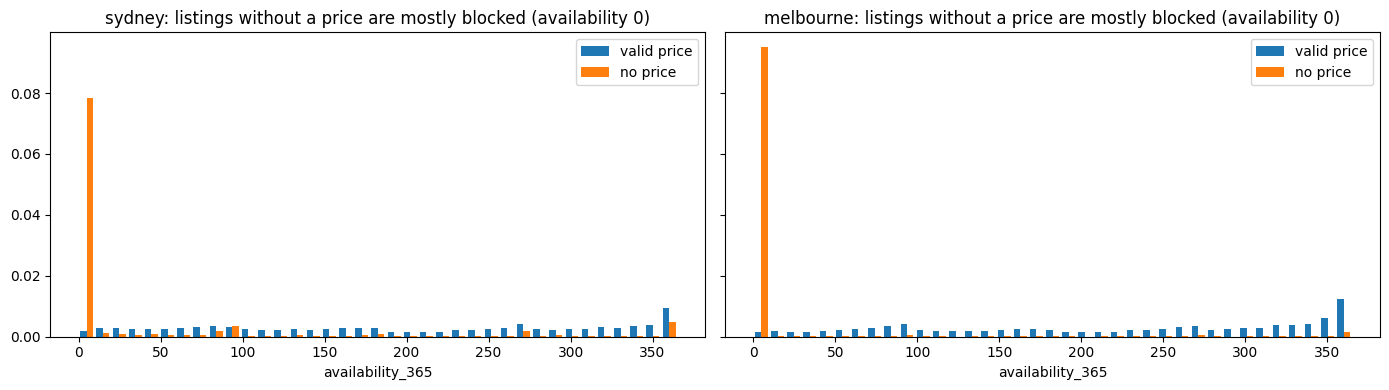

In [0]:
fig, axes = plt.subplots(1, len(CITIES), figsize=(7 * len(CITIES), 4), squeeze=False, sharey=True)
for ax, city in zip(axes[0], CITIES):
    g = df_all[df_all.city == city]
    valid = g["is_valid_price"].fillna(False).astype(bool)
    ax.hist([g.loc[valid, "availability_365"], g.loc[~valid, "availability_365"]], bins=37,
            label=["valid price", "no price"], density=True)
    ax.set_title(f"{city}: listings without a price are mostly blocked (availability 0)")
    ax.set_xlabel("availability_365"); ax.legend()
plt.tight_layout(); plt.show()

**Reading (check against the tables above):** listings without a price have far more `availability_365 = 0`, `has_availability` false and no reviews in the last year. They are inactive or delisted, so Inside Airbnb has no advertised price for them.
**Decision:** keep them in silver (they still count as listings for the dashboard), exclude them from price analysis, the baseline and the model (`is_valid_price = true` only). Melbourne's higher share means more inactive listings, not worse data.

### 2.2 Other missing values (listings with a valid price)
Missing values stay **NULL** in silver. Filling them is a modelling choice, learned on the training split only.

In [0]:
miss = eda.missing_table(df, PROFILE_COLS)
display(miss[miss.max(axis=1) > 0].rename(columns=lambda c: f"{c} % NULL").reset_index(names="column"))

column,melbourne % NULL,sydney % NULL
host_tenure_days,100.0,100.0
host_acceptance_rate,100.0,100.0
host_response_rate,100.0,100.0
host_response_time,100.0,100.0
instant_bookable,100.0,100.0
review_scores_rating,15.1,14.5
first_review,15.1,14.5
last_review,15.1,14.5
reviews_per_month,15.1,14.5
review_scores_cleanliness,15.1,14.5


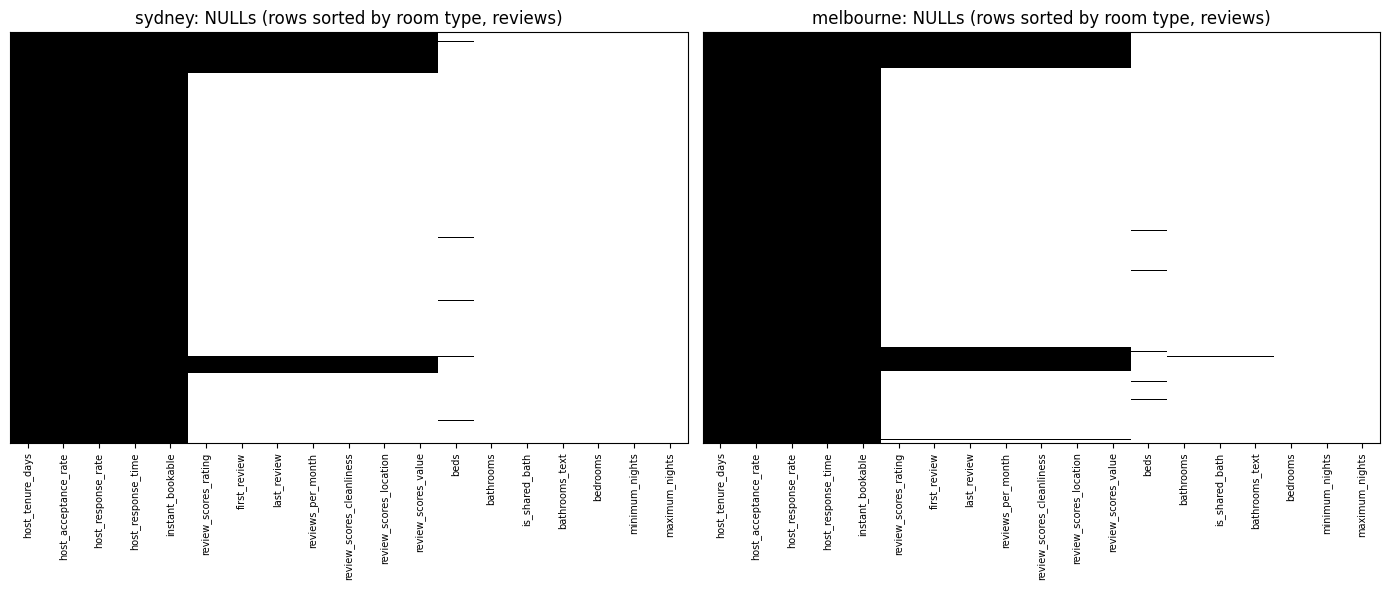

In [0]:
# Where the gaps are: rows (sorted by room type, then number of reviews) x columns. Black = NULL.
cols = miss.index[miss.max(axis=1) > 0].tolist()
fig, axes = plt.subplots(1, len(CITIES), figsize=(7 * len(CITIES), 6), squeeze=False)
for ax, city in zip(axes[0], CITIES):
    g = df[df.city == city].sort_values(["room_type", "number_of_reviews"])
    ax.imshow(g[cols].isna().to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")
    ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=7)
    ax.set_yticks([]); ax.set_title(f"{city}: NULLs (rows sorted by room type, reviews)")
plt.tight_layout(); plt.show()

In [0]:
# Missing for a reason? Missing rate when the condition is true vs false. A big gap = a pattern.
display(eda.missing_patterns(df))

city,missing_column,condition,rows_condition_true,missing_if_true_%,missing_if_false_%
melbourne,review_scores_rating,number_of_reviews == 0,2864,100.0,0.0
sydney,review_scores_rating,number_of_reviews == 0,2575,100.0,0.0
melbourne,review_scores_accuracy,number_of_reviews == 0,2864,100.0,0.0
sydney,review_scores_accuracy,number_of_reviews == 0,2575,100.0,0.0
melbourne,review_scores_cleanliness,number_of_reviews == 0,2864,100.0,0.0
sydney,review_scores_cleanliness,number_of_reviews == 0,2575,100.0,0.0
melbourne,review_scores_checkin,number_of_reviews == 0,2864,100.0,0.0
sydney,review_scores_checkin,number_of_reviews == 0,2575,100.0,0.0
melbourne,review_scores_communication,number_of_reviews == 0,2864,100.0,0.0
sydney,review_scores_communication,number_of_reviews == 0,2575,100.0,0.0


**Reading (check against the output):**
- **Review scores, `reviews_per_month`, `first_review`** are NULL when `number_of_reviews = 0`: *not applicable*. The model gets a `has_reviews` flag instead of a mean fill.
- **`bedrooms`, `beds`** are NULL mostly for private/shared rooms and small listings (studios): the host left it empty. Fill on train only, e.g. median by `room_type` × `accommodates`.
- **`bathrooms`** is filled from `bathrooms_text` in silver; what is left NULL has no text either.
- **Host response fields** are NULL together: the host has had no requests to answer. Treat as their own category.

### 2.3 Price distribution (valid prices)

In [0]:
display(eda.price_summary(df).reset_index())

city,room_type,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
melbourne,Entire home/apt,14504.0,407.6,1438.7,51.0,118.4,156.0,229.5,301.7,412.7,816.0,1705.0,109084.5
melbourne,Hotel room,44.0,402.9,175.8,207.6,208.9,213.8,296.0,355.5,460.2,672.3,999.0,999.0
melbourne,Private room,4253.0,207.9,2309.5,15.0,44.2,56.1,82.0,109.0,151.0,335.0,749.0,101830.5
melbourne,Shared room,203.0,64.6,81.3,23.9,25.2,29.1,37.5,48.9,65.2,135.3,323.0,799.0
sydney,Entire home/apt,13899.0,605.6,1511.2,56.1,125.5,177.5,284.3,394.0,583.0,1551.0,3880.5,96887.6
sydney,Hotel room,53.0,294.4,94.9,118.7,125.1,151.4,228.0,291.0,351.0,456.0,523.3,558.0
sydney,Private room,3726.0,170.6,448.1,16.9,43.0,57.0,90.8,124.7,178.9,344.8,723.0,19689.8
sydney,Shared room,43.0,79.7,50.3,34.6,35.2,38.9,57.8,66.0,77.6,176.8,252.1,304.3


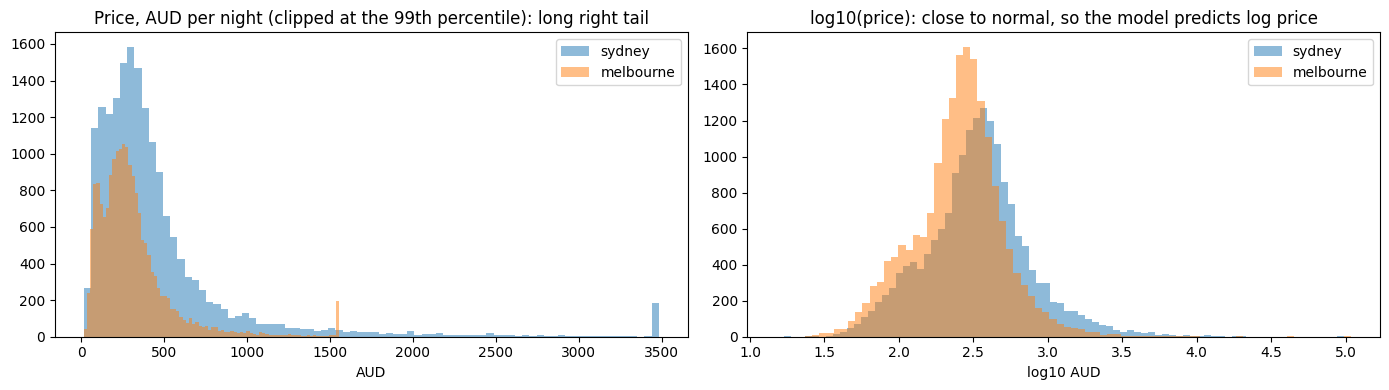

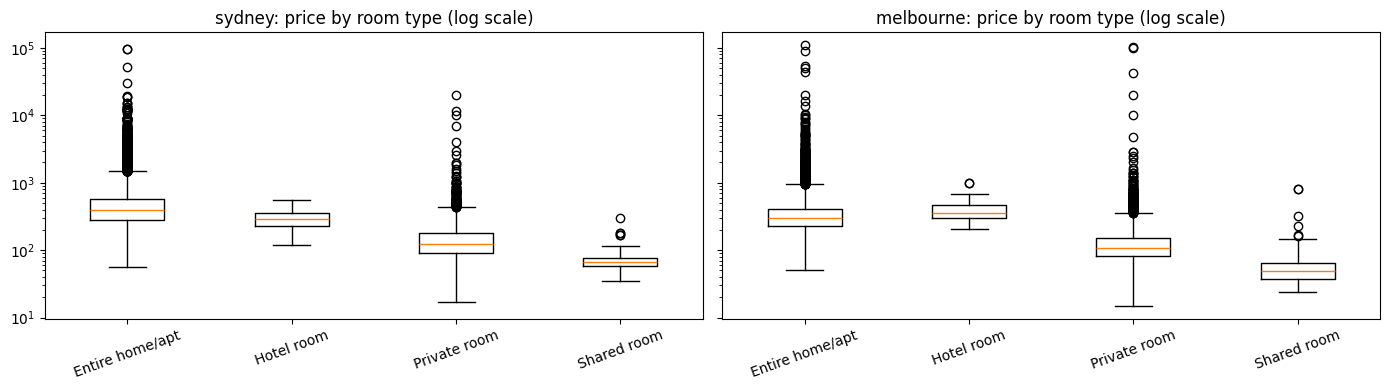

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for city in CITIES:
    p = df.loc[df.city == city, "price"]
    axes[0].hist(p.clip(upper=p.quantile(.99)), bins=80, alpha=.5, label=city)
    axes[1].hist(np.log10(p), bins=80, alpha=.5, label=city)
axes[0].set_title("Price, AUD per night (clipped at the 99th percentile): long right tail"); axes[0].set_xlabel("AUD")
axes[1].set_title("log10(price): close to normal, so the model predicts log price"); axes[1].set_xlabel("log10 AUD")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(CITIES), figsize=(7 * len(CITIES), 4), squeeze=False, sharey=True)
for ax, city in zip(axes[0], CITIES):
    g = df[df.city == city]
    groups = sorted(g.room_type.dropna().unique())
    ax.boxplot([g.loc[g.room_type == r, "price"] for r in groups], whis=3)
    ax.set_xticks(range(1, len(groups) + 1), groups)
    ax.set_yscale("log"); ax.set_title(f"{city}: price by room type (log scale)"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [0]:
# Median price by room type x accommodates: this grid is the baseline the model must beat
grid = df.groupby(["city", "room_type", "accommodates"])["price"].median().unstack(["city", "room_type"])
display(grid.round(0).reset_index())

"('accommodates', '')","('melbourne', 'Entire home/apt')","('melbourne', 'Hotel room')","('melbourne', 'Private room')","('melbourne', 'Shared room')","('sydney', 'Entire home/apt')","('sydney', 'Hotel room')","('sydney', 'Private room')","('sydney', 'Shared room')"
1,140.0,null,93.0,46.0,156.0,237.0,99.0,65.0
2,222.0,396.0,111.0,48.0,277.0,298.0,127.0,174.0
3,236.0,null,128.0,38.0,309.0,267.0,167.0,41.0
4,303.0,315.0,191.0,51.0,386.0,335.0,200.0,96.0
5,311.0,403.0,242.0,65.0,421.0,null,311.0,null
6,378.0,508.0,320.0,51.0,514.0,null,365.0,42.0
7,404.0,675.0,256.0,null,571.0,null,329.0,null
8,463.0,null,388.0,null,754.0,null,519.0,36.0
9,450.0,null,678.0,null,697.0,null,540.0,null
10,532.0,null,574.0,null,809.0,null,660.0,null


### 2.4 Availability distribution (valid prices)

city,0 (blocked),1-89,90-179,180-269,270-364,365 (always open)
melbourne,0.1,21.0,19.1,18.4,38.5,3.0
sydney,0.1,24.1,23.0,18.9,31.0,3.0


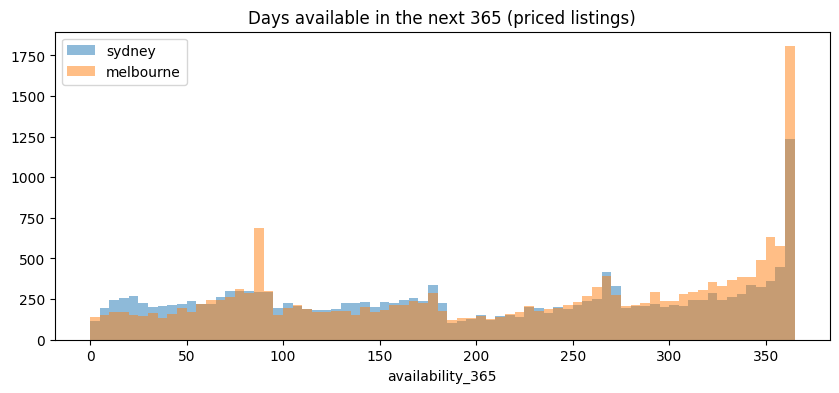

In [0]:
display(eda.availability_summary(df).reset_index())
fig, ax = plt.subplots(figsize=(10, 4))
for city in CITIES:
    ax.hist(df.loc[df.city == city, "availability_365"], bins=73, alpha=.5, label=city)
ax.set_title("Days available in the next 365 (priced listings)"); ax.set_xlabel("availability_365"); ax.legend()
plt.show()

### 2.5 Outliers and how we classify them
Fences on **log price**, per city × room type, at Q1 − 3·IQR and Q3 + 3·IQR (groups under 30 listings use the city's fences). Wide on purpose: separate *impossible* from *rare but real*.

| Class | Meaning | Pipeline / model |
|---|---|---|
| `placeholder` | above the high fence and a typed-looking number (9999, 10000, 99999) | flag, drop from train and test |
| `high_outlier` / `low_outlier` | outside the fences, plausible after inspection | keep, flag `is_price_outlier`; log price limits their pull |
| `long_stay` | `minimum_nights > 30`: a monthly rental | keep, flag, exclude from the model |
| `normal` | everything else | keep |

In [0]:
df = eda.classify_price(df)
display(pd.crosstab(df["city"], df["price_class"], margins=True).reset_index())

city,high_outlier,long_stay,normal,placeholder,All
melbourne,92,109,18792,11,19004
sydney,89,1722,15908,2,17721
All,181,1831,34700,13,36725


In [0]:
# Inspect by hand: luxury homes or errors?
show = ["city", "id", "price", "price_class", "price_high_fence", "room_type", "property_type",
        "accommodates", "bedrooms", "minimum_nights", "availability_365", "number_of_reviews", "name"]
show = [c for c in show if c in df]
display(df[df.price_class.isin(["placeholder", "high_outlier"])].sort_values("price", ascending=False)[show].head(30))
low = df[df.price_class == "low_outlier"].sort_values("price")[show].head(15)
print("Low outliers:", len(low)); display(low) if len(low) else None

city,id,price,price_class,price_high_fence,room_type,property_type,accommodates,bedrooms,minimum_nights,availability_365,number_of_reviews,name
melbourne,1095956825302874703,109084.5,high_outlier,2399.0,Entire home/apt,Entire home,6,2.0,2.0,16,86,"Albert Park Home Sleeps 6. City, Beach & Lake"
melbourne,34589429,101830.54,high_outlier,943.0,Private room,Private room in villa,2,1.0,70.0,365,5,Brand new tidy rooms Modern house Great location
melbourne,856669005861616353,99999.0,placeholder,943.0,Private room,Private room in rental unit,2,1.0,1.0,270,0,The marker Apartment
sydney,1192424755970639194,96887.58,high_outlier,5028.0,Entire home/apt,Entire townhouse,6,3.0,100.0,270,4,Sydney Inner-City Luxury Architectural Home-Hotel
sydney,1172314473011066918,96887.58,high_outlier,5028.0,Entire home/apt,Entire home,6,3.0,100.0,270,3,SYD Inner-City Award-Winning Luxury Designer House
melbourne,1760711875863103315,90000.0,placeholder,2399.0,Entire home/apt,Entire home,4,2.0,1.0,168,0,2608
melbourne,1760696883895618013,54496.0,high_outlier,2399.0,Entire home/apt,Entire home,10,3.0,1.0,120,0,4102
sydney,948190865551462634,52850.0,high_outlier,5028.0,Entire home/apt,Entire rental unit,6,2.0,1.0,49,5,Sublime Sydney views
melbourne,1760698261731463509,50000.0,placeholder,2399.0,Entire home/apt,Entire home,5,2.0,1.0,281,0,2606
melbourne,712782536746112483,43849.62,high_outlier,2399.0,Entire home/apt,Entire loft,7,3.0,365.0,365,0,"Unique, Luxury Penthouse With Stunning CBD Views"


Low outliers: 0


In [0]:
# Other values outside what is physically plausible (counts per city)
display(eda.other_outliers(df).reset_index())

rule,melbourne,sydney
accommodates > 16 (Airbnb caps at 16),0,0
bathrooms > 10,5,5
bedrooms > accommodates,135,75
beds == 0,0,0
host_listings_count > 100,1567,1188
maximum_nights > 1125 (Airbnb default max),17,2
minimum_nights > 365,0,0


## 3. Cleaning the pipeline must do
Each rule, its reason, and whether `silver.py` already does it.

| # | Rule | Reason (section) | In silver.py |
|---|---|---|---|
| 1 | Read every column as text in bronze | the file mixes `"$1,234.00"`, `"95%"`, `"t"/"f"`; guessing types loses values | ✅ bronze |
| 2 | One row per `id` (keep latest `last_scraped`) | grain is one listing (1) | ✅ |
| 3 | `price`: strip `$`, `,` → double | target arrives as text (2.3) | ✅ |
| 4 | `is_valid_price = price IS NOT NULL AND price > 0`; keep the rows, exclude from price work | missing price = inactive listing (2.1) | ✅ flag; filter in features/model |
| 5 | Empty string and `N/A` → NULL; leave NULLs as NULL | filling is a model step, learned on train only (2.2) | ✅ |
| 6 | Percentages → 0..1, `t`/`f` → boolean, dates → date | text types (2) | ✅ |
| 7 | `bathrooms` from `bathrooms_text` when empty; `is_shared_bath` | `bathrooms` often empty (2.2) | ✅ |
| 8 | `host_tenure_days` against `snapshot_date`, never `current_date()` | reproducible on any day | ✅ |
| 9 | Flag `is_long_stay = minimum_nights > 30` | nightly price means something else (2.5) | ➕ to add |
| 10 | Flag placeholder prices (above fence and 9999/10000/99999 pattern) | typed-in values (2.5) | ➕ to add |
| 11 | `has_reviews = number_of_reviews > 0` | review NULLs are structural (2.2) | ➕ to add (or in features) |
| 12 | Check `room_type` against the 4 known values, log unseen ones | a new city can bring new categories (week 2) | ➕ to add to validation |
| 13 | Drop leakage, id and metadata columns from the **feature** table, not from silver | section 4 | ➕ `features.py` |

## 4. Leakage review
The target is the advertised nightly `price` on the snapshot date. A column leaks if it is **computed from the price** or **states it**.
Four tests: names, correlations, an exact check of the formula behind the suspicious column, and the free text.

In [0]:
print("Raw columns whose name points to money:   ", eda.leakage_name_scan(raw_cols))
print("Silver columns whose name points to money:", eda.leakage_name_scan(df_all.columns))

Raw columns whose name points to money:    ['price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw', 'estimated_revenue_l365d']
Silver columns whose name points to money: ['estimated_revenue_l365d']


In [0]:
# Spearman correlation with price (valid prices). High alone is NOT leakage: accommodates is a real driver.
# It only says which columns to examine.
display(eda.leakage_correlations(df).head(20).reset_index(names="column"))

column,melbourne,sydney
accommodates,0.695,0.714
bedrooms,0.657,0.668
beds,0.606,0.647
bathrooms,0.416,0.461
longitude,0.086,0.368
amenities_count,0.326,0.336
review_scores_location,0.16,0.328
estimated_revenue_l365d,0.311,0.241
review_scores_rating,0.09,0.23
review_scores_accuracy,0.084,0.204


In [0]:
# The decisive check: is estimated_revenue_l365d exactly price x estimated_occupancy_l365d?  (all silver rows)
display(eda.revenue_identity(df_all))

city,rows_checked,median_ratio,identity_holds_within_1pct_%,revenue_null_when_price_null_%
melbourne,14368,1.0,100.0,100.0
sydney,13512,1.0,100.0,100.0


In [0]:
# Does the free text state the price? % of listings with "$<digits>" in name / description (bronze)
display(eda.price_in_text(spark, CITIES))

city,name,description
melbourne,0.05,1.47
sydney,0.06,1.16


### Conclusion
**Leakage: never a feature** (`features.LEAKAGE_COLS`)

| Column | Why |
|---|---|
| `estimated_revenue_l365d` | Inside Airbnb computes it as price × estimated booked nights: the identity check holds for almost every row, and it is NULL exactly when price is NULL. Using it is using the target. |
| `price`, `is_valid_price`, anything derived from price (price per guest, `price_class`) | the target itself or a function of it |

**Not leakage, but never features** (`features.NON_FEATURE_COLS`): `id`, `host_id`, `last_scraped`, `snapshot_date`, `_ingested_at`, `license`, `name` and the raw URLs / scrape metadata (not in silver). They describe the scrape, not the listing, or let a model memorise rows.

**Free text** (`name`, `description`): a small share writes the price in the text (table above). Raw text is not used; if it ever is, strip `$<number>` first.

**Allowed, with care** (`features.CAUTION_COLS`): `estimated_occupancy_l365d`, `availability_*`, `number_of_reviews_ltm`. Not computed from price (occupancy comes from reviews and minimum nights), but they react to it over time (expensive listings book less). Out of the first model; added only if they clearly help on the test set.

**Transfers badly to city C:** `neighbourhood_cleansed`: its values do not exist in another city. Prefer room type, size, amenities, distance to the city centre from latitude/longitude.

## 5. For city C (week 2, with P1)
The same helpers profile a new city once the pipeline has run on it. In `03_city_c`, after the unchanged first run:
```python
cmp = eda.compare_to_training(spark, "brisbane")
for name, table in cmp.items(): print(name); display(table)
```
It lists raw columns empty or new in C, unseen `room_type` / `property_type` / neighbourhoods, the share without a price and why, price and size distributions next to A and B, NULL rates and outlier classes. Each difference becomes a *pipeline fix* or a *model change* in `docs/city_c_report.md`.

### Facts for the summary

In [0]:
facts = {}
rev = eda.revenue_identity(df_all).set_index("city")
for city in CITIES:
    a, v = df_all[df_all.city == city], df[df.city == city]
    facts[city] = {
        "snapshot": str(a["snapshot_date"].max().date()),
        "silver rows": len(a),
        "bronze - silver (duplicates / no id)": int(overview.loc[city, "bronze_minus_silver"]),
        "no valid price %": round((~a["is_valid_price"].fillna(False).astype(bool)).mean() * 100, 1),
        "valid-price listings": len(v),
        "median price AUD": float(v["price"].median()),
        "placeholder prices": int((v.price_class == "placeholder").sum()),
        "high / low outliers": int(v.price_class.isin(["high_outlier", "low_outlier"]).sum()),
        "long stay": int((v.price_class == "long_stay").sum()),
        "revenue identity holds %": rev.loc[city].get("identity_holds_within_1pct_%"),
    }
display(pd.DataFrame(facts).reset_index(names="fact"))

fact,sydney,melbourne
snapshot,2026-09-16,2026-09-16
silver rows,20833,25715
bronze - silver (duplicates / no id),0,0
no valid price %,14.9,26.1
valid-price listings,17721,19004
median price AUD,337.8,263.21000000000004
placeholder prices,2,11
high / low outliers,89,92
long stay,1722,109
revenue identity holds %,100.0,100.0
